In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from tqdm import tqdm

from utils.model import cosine_kernel_fft, kuramoto_kernel

BASE_FOLDER = Path("./paper_plots/")
BASE_FOLDER.mkdir(parents=True, exist_ok=True)

In [2]:
N = 1024
A = 0.995
alpha = (np.pi / 2) - 0.16
kernel_fft = cosine_kernel_fft(A, N)


omegas = np.zeros(N)

np.random.seed(seed=1338)

evolve_time = 1000.0
dt = 0.1

initial_conditions = (
    6.0
    * np.exp(-0.76 * (np.linspace(-np.pi, np.pi, N, endpoint=False)) ** 2)
    * (np.random.random(N) - 0.5)
)

In [3]:
kuramoto = kuramoto_kernel(omegas, kernel_fft, alpha=alpha)
t_evolve_eval = np.arange(0, evolve_time + dt, dt)
t_evolve_span = (0, evolve_time + dt)

sol = solve_ivp(
    lambda _, y: kuramoto(y),
    t_evolve_span,
    initial_conditions,
    t_eval=t_evolve_eval,
    method="RK45",
    rtol=1e-7,
    atol=1e-10,
)
init_state = sol.y.T

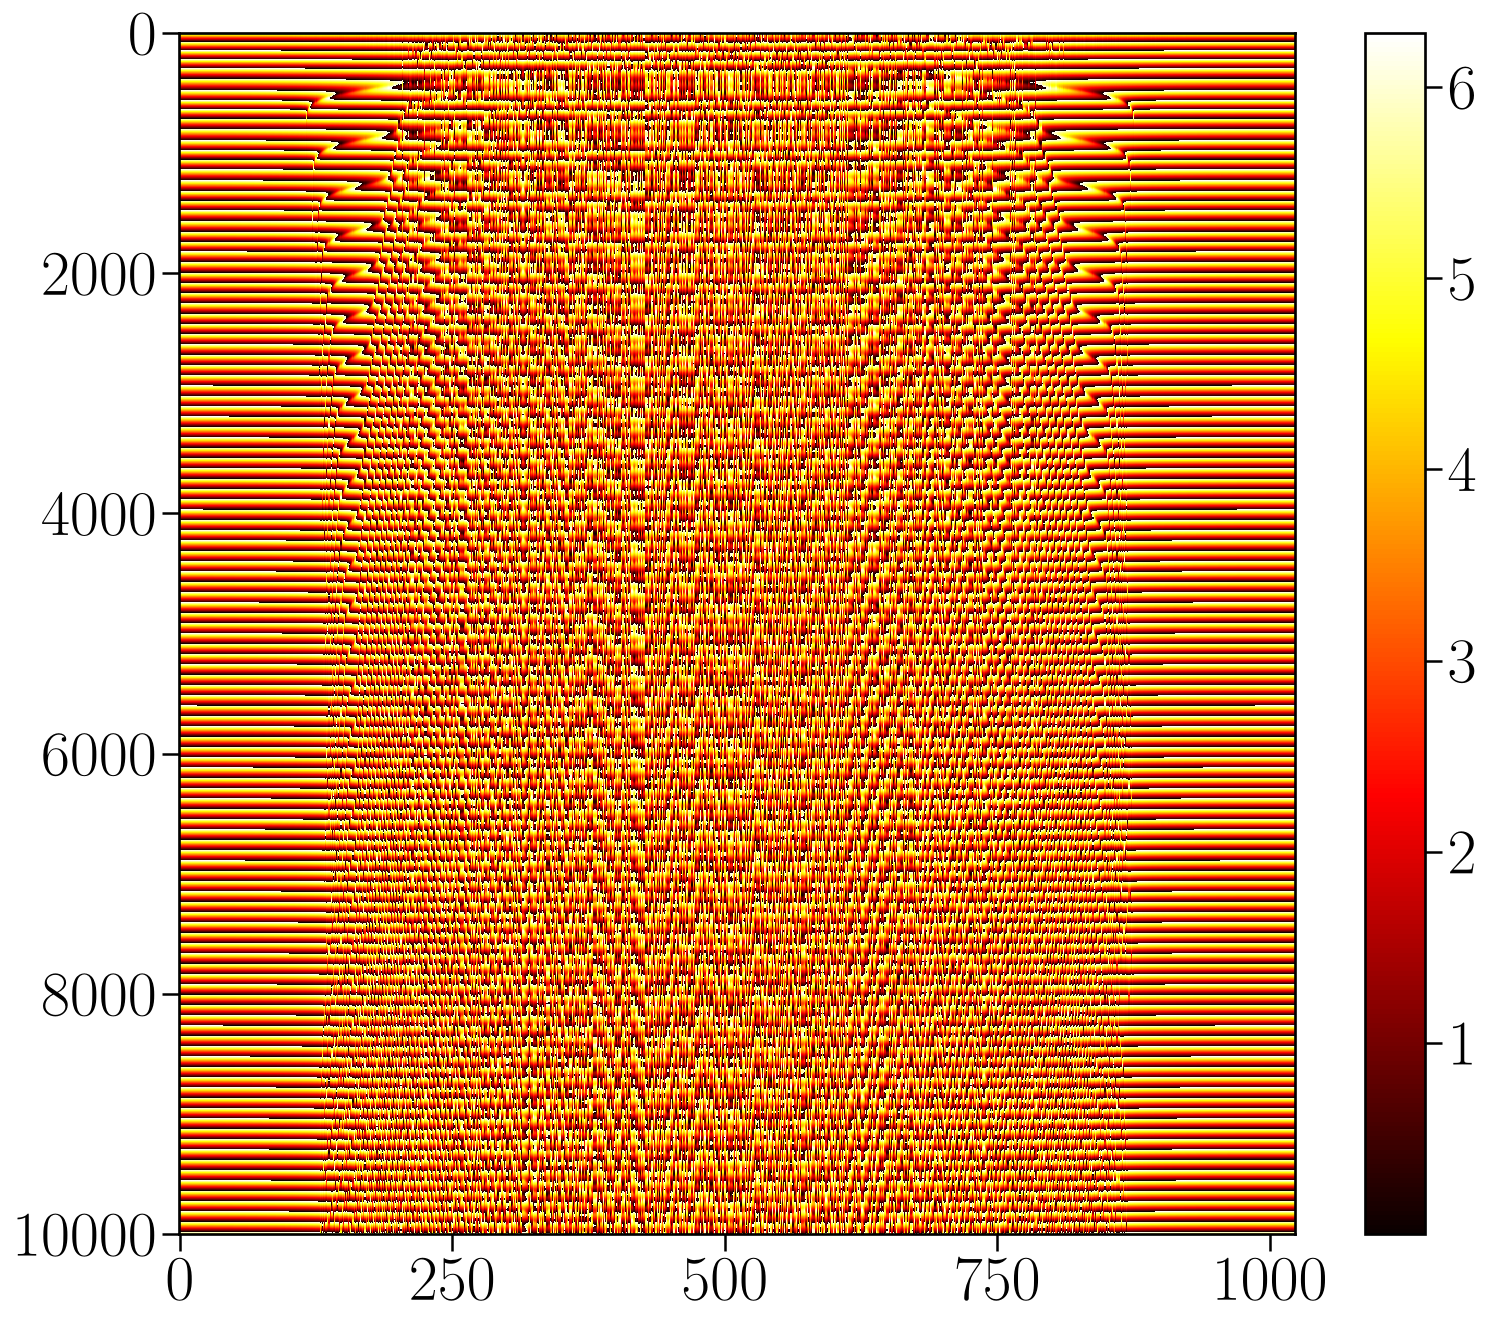

In [4]:
plt.figure()
heatmap = plt.imshow(
    init_state % (2 * np.pi), aspect="auto", interpolation="none", cmap="hot"
)
plt.colorbar(heatmap)
plt.show()

In [5]:
beta_positions = np.linspace(0, N, 8, endpoint=True, dtype=int)
mid_indices = len(beta_positions) // 2 - 1, len(beta_positions) // 2
beta_positions[0] += 5
beta_positions[-1] -= 5
beta_positions

array([   5,  146,  292,  438,  585,  731,  877, 1019])

In [6]:
solutions_cos = []
x = np.linspace(-np.pi, np.pi, N, endpoint=False)
new_omegas = omegas + 0.05 * np.cos(x)
sim_omegas = new_omegas.copy()
for beta in tqdm(beta_positions):
    sim_omegas = np.roll(new_omegas, beta)
    kuramoto = kuramoto_kernel(sim_omegas, kernel_fft, alpha=alpha)
    t_evolve_eval = np.arange(0, evolve_time * 2 + dt, dt)
    t_evolve_span = (0, evolve_time * 2 + dt)

    sol = solve_ivp(
        lambda _, y: kuramoto(y),
        t_evolve_span,
        init_state[-1],
        t_eval=t_evolve_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-10,
    )
    solutions_cos.append(sol)

100%|██████████| 8/8 [00:08<00:00,  1.01s/it]


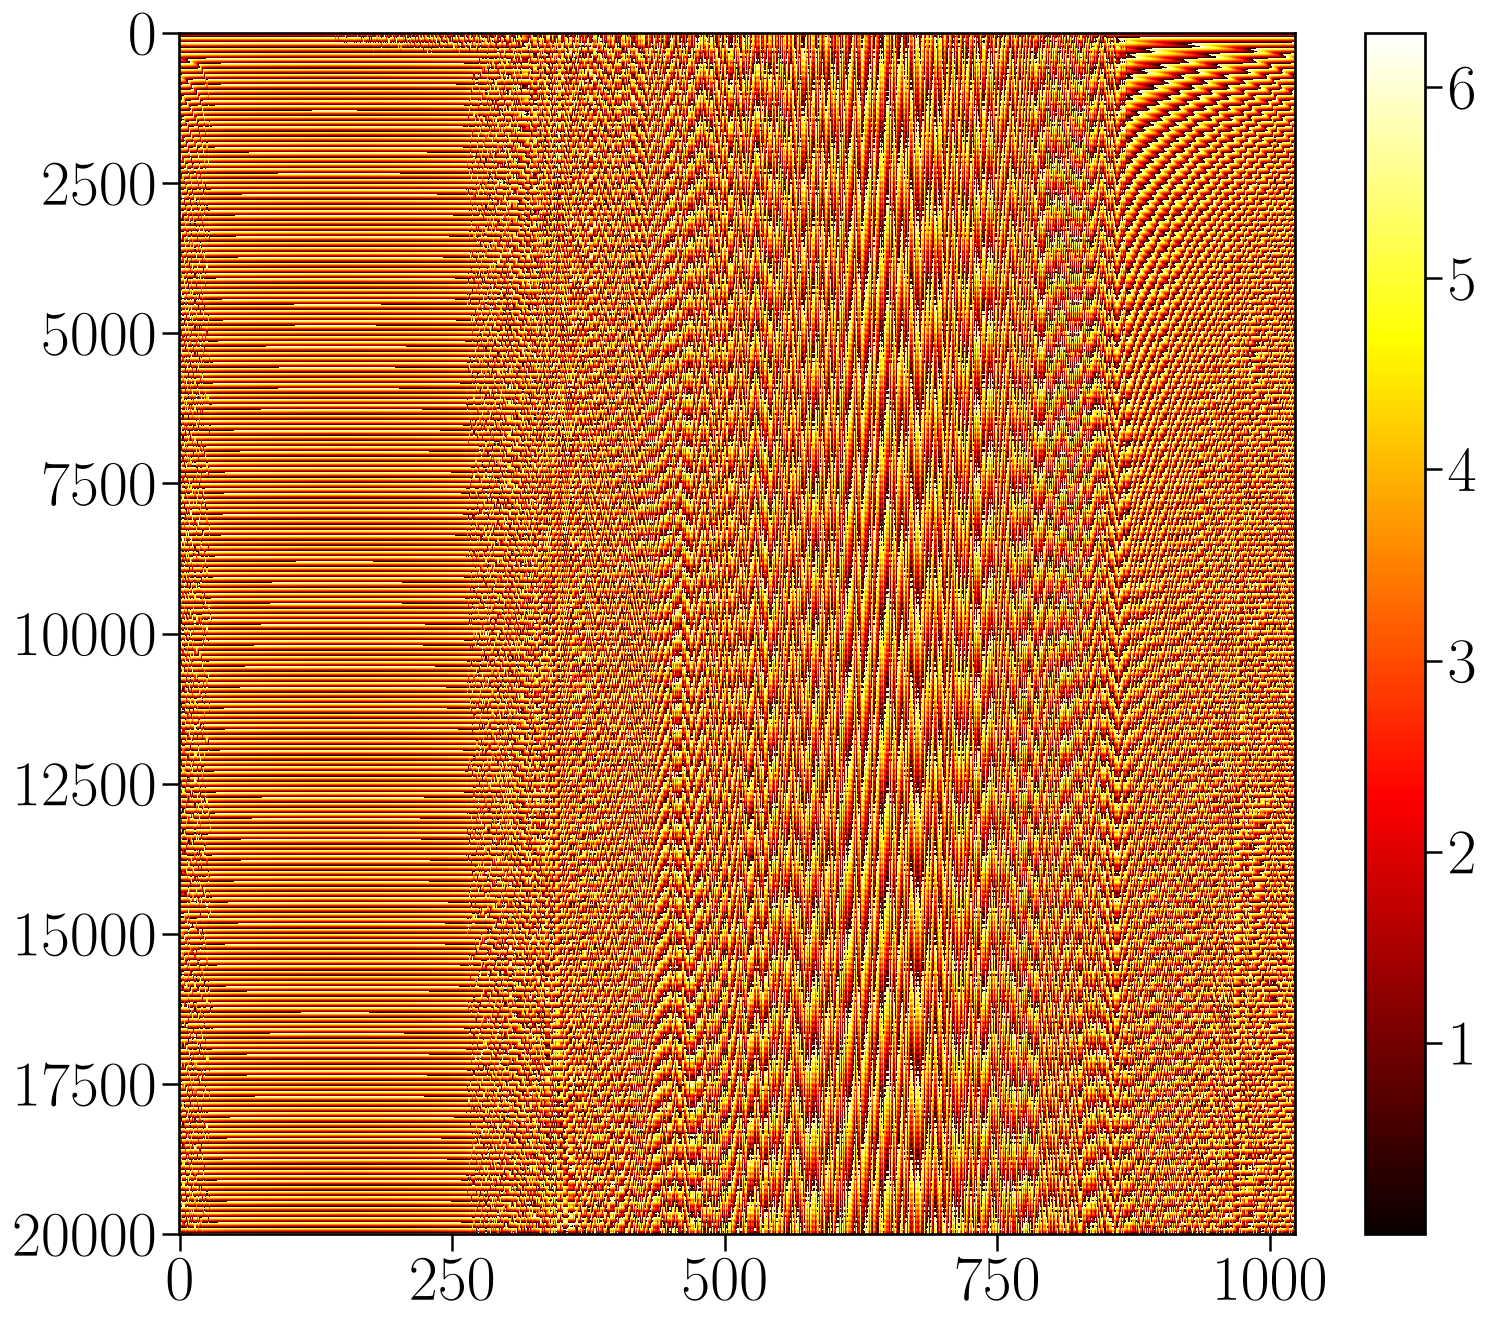

In [7]:
plt.figure()
heatmap = plt.imshow(
    solutions_cos[1].y.T % (2 * np.pi), aspect="auto", interpolation="none", cmap="hot"
)
plt.colorbar(heatmap)
plt.show()

In [8]:
DIRAC_HALF_WIDTH = 10  # perturb oscillators beta-10 ... beta+10
DIRAC_STRENGTH = 0.2  # frequency shift applied to the perturbed oscillators

solutions_dirac = []
for beta in tqdm(beta_positions):
    new_omegas = omegas.copy()
    window = np.arange(beta - DIRAC_HALF_WIDTH, beta + DIRAC_HALF_WIDTH + 1) % N
    new_omegas[window] += DIRAC_STRENGTH
    kuramoto = kuramoto_kernel(new_omegas, kernel_fft, alpha=alpha)
    t_evolve_eval = np.arange(0, evolve_time * 6 + dt, dt)
    t_evolve_span = (0, evolve_time * 6 + dt)
    sol = solve_ivp(
        lambda _, y: kuramoto(y),
        t_evolve_span,
        init_state[-1],
        t_eval=t_evolve_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-10,
    )
    solutions_dirac.append(sol)


100%|██████████| 8/8 [00:25<00:00,  3.16s/it]


In [9]:
frequencies_dirac = []
for sol in solutions_dirac:
    sim_state = sol.y.T
    sim_state = sim_state[-sim_state.shape[0] // 3 :]
    state_sim = np.unwrap(sim_state, axis=0)
    omega_sim = (np.diff(state_sim, axis=0)).mean(axis=0) / dt
    frequencies_dirac.append(omega_sim)

omegas_per_sim = [np.min(freq) for freq in frequencies_dirac]
coherent_freqs_dirac = []
epsilon = 0.01
for i, freqs in enumerate(frequencies_dirac):
    c_freq = np.array(
        [
            not (omegas_per_sim[i] - epsilon <= point <= omegas_per_sim[i] + epsilon)
            for point in freqs
        ]
    )
    coherent_freqs_dirac.append(c_freq)

In [10]:
frequencies_cos = []
for sol in solutions_cos:
    sim_state = sol.y.T
    sim_state = sim_state[-sim_state.shape[0] // 3 :]
    state_sim = np.unwrap(sim_state, axis=0)
    omega_sim = (np.diff(state_sim, axis=0)).mean(axis=0) / dt
    frequencies_cos.append(omega_sim)

omegas_per_sim = [np.min(freq) for freq in frequencies_cos]
coherent_freqs_cos = []
epsilon = 0.01
for i, freqs in enumerate(frequencies_cos):
    c_freq = np.array(
        [
            not (omegas_per_sim[i] - epsilon <= point <= omegas_per_sim[i] + epsilon)
            for point in freqs
        ]
    )
    coherent_freqs_cos.append(c_freq)

In [11]:
def find_circular_central_index(bool_array):
    n = len(bool_array)
    extended_array = np.concatenate([bool_array, bool_array])

    # Find indices of True values in the extended array
    true_indices = np.where(extended_array)[0]

    # Identify the start and end indices of the longest contiguous subarray of True values
    max_length = 0
    current_start = true_indices[0]
    current_length = 1
    best_start = current_start

    for i in range(1, len(true_indices)):
        if true_indices[i] == true_indices[i - 1] + 1:
            current_length += 1
        else:
            if current_length > max_length:
                max_length = current_length
                best_start = current_start
            current_start = true_indices[i]
            current_length = 1

    # Check the last subarray
    if current_length > max_length:
        max_length = current_length
        best_start = current_start

    # Calculate the central index of the longest contiguous subarray
    central_index = (best_start + best_start + max_length - 1) // 2

    # Adjust the index to be within the original array bounds
    central_index = central_index % n

    return central_index


# Example usage
centers_dirac = np.array(
    [find_circular_central_index(el) for el in coherent_freqs_dirac]
)
centers_cos = np.array([find_circular_central_index(el) for el in coherent_freqs_cos])

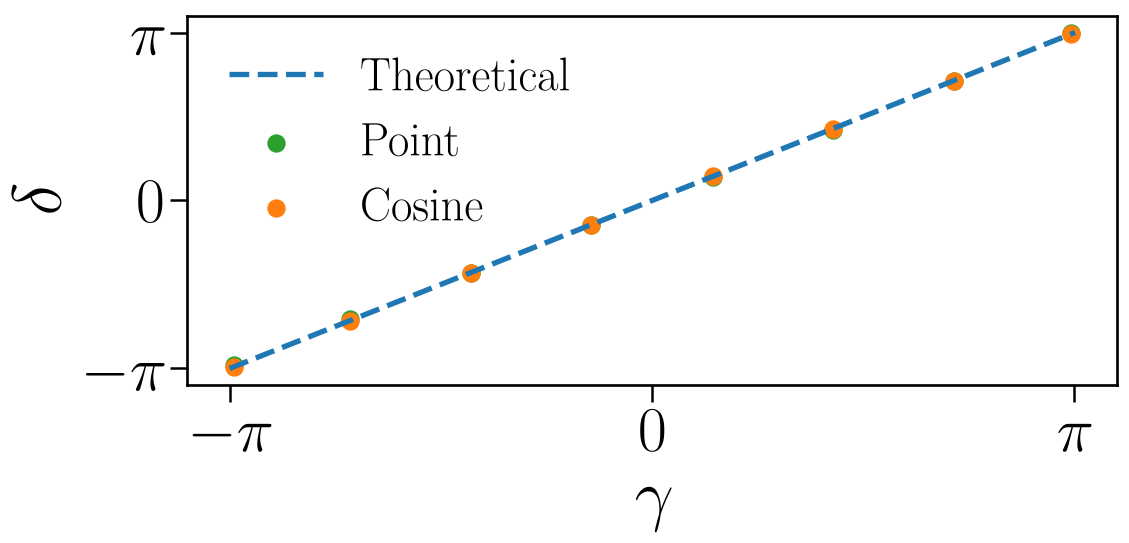

In [12]:
fig = plt.figure(figsize=(10, 4))
plt.plot([0, N], [0, N], label="Theoretical", linestyle="--")

plt.scatter(beta_positions, centers_dirac, s=100, c="tab:green", label="Point")
plt.scatter(
    beta_positions, (centers_cos + N // 2) % N, s=100, c="tab:orange", label="Cosine"
)

plt.xlabel(r"$\gamma$")
plt.ylabel(r"$\delta$")
plt.xticks(ticks=[0, N / 2, N - 1], labels=[r"$-\pi$", r"$0$", r"$\pi$"])
plt.yticks(ticks=[0, N / 2, N - 1], labels=[r"$-\pi$", r"$0$", r"$\pi$"])
plt.legend()
plt.savefig(BASE_FOLDER / "4.pdf", bbox_inches="tight")
plt.show()